# GW-only: can order-based Gromov–Wasserstein matching recover where A's points sit in B?

## Description

<!-- Written before the first run (2026-10-26, ~10:30). Criteria drafted by Claude (autonomous); issue #13,
design: docs/brainstorm_2026-10-23_registration.md §9–10, decision 0003. -->

### The problem, standalone

Two related tasks share the search space [0, 1]. **A** is scarce: n_A observations (x_a, y_a). **B** is dense:
N_B observations (u_b, y_b) of a *transformed* copy of A's function: f_B(u) = f_A(T(u)), with T an unknown increasing
map (in this experiment the output map h is the identity; each task is still normalized on its own window, so B's
values are an affine-rescaled copy). If T were known, every B point could be placed in A's frame at
B_inA = (T(u_b), y_b on A's scale) and used as extra data for A. The registration problem is to recover T from the
data alone.

This notebook tests one component of the planned registration model in **isolation**: the front half, which finds a
few **landmarks**, i.e. for each A point the B point(s) it corresponds to. The truth for A point a is
u*_a = T⁻¹(x_a), the location in B's frame of the B point that sits at x_a in A's frame (computed from the
privileged B_inA of the prior; an A point is *covered* if x_a lies inside T's image of B's window, about 85–100% of
them). The back half (a displacement field that spreads the landmarks to all B points and refines them) is tested
separately (notebook 04).

### Prior (data)

Phase-1 pair prior (`experimental/regpfn/prior.py`), d = 1: f_A is a random BNN draw (pfn-repro's BNN prior, evaluated
on all of R so that shifted windows stay defined); T(u) = Kumaraswamy-warp(0.5 + a (u + s − 0.5)) with shift
s ~ U[−0.3, 0.3], scale a ~ logU[0.7, 1.4], warp log α, log β ~ N(0, 0.35²). Cells: **C00** (T = id: B is A's own
function, a sanity stratum) and **C10** (T on; the question). Each task is normalized affinely onto [0.1, 0.9] over its
own window; observation noise σ ~ logU[1e-3, 3e-2]. N_B = 64 (small scale), n_A ∈ {2, 5, 10, 20}. Evaluation:
256 fixed pairs per cell (the same pair construction as notebook 04, at N_B = 64), nested in n_A.

### Components

**Order relations.** For two points i, j of the same task: s(i, j) = (sign(x_i − x_j), sign(y_i − y_j)) ∈ {−1, 0, 1}².
They are unchanged by any increasing T and any increasing output map, and do not depend on how densely a region is
sampled. Nothing metric is used.

**GW objective (semi-relaxed).** A coupling π ∈ R^{n_A × N_B}, each row a distribution over B (every A point is
matched; B's marginal is free, since B points outside A's window have no partner):
  E(π) = (1/n_A) Σ_{a, a', b, b'} |s_A(a, a') − s_B(b, b')|² π_ab π_a'b'.
It is small when pairs of matches agree in order: if a is left of and below a', then a's partner should be left of
and below a''s partner.

**Solver 1, `peyre` (no learning).** Mirror descent on the row logits, L ← L − η ∇E(π), π = row-softmax(L), η = 1,
200 iterations; this is the semi-relaxed form of entropic GW (Peyré, Cuturi & Solomon 2016; Vincent-Cuaz et al. 2022;
to verify). E is non-convex: restart 0 starts from the uniform coupling, restarts 1–7 from random logits; **K = 1**
reports the restart with the lowest energy, **best-of-8** the restart closest to the truth (an oracle choice: the
recall a K = 8 hypothesis model could reach).

**Solver 2, `unrolled` (learned GW).** The same iteration, made learnable and weight-tied (10 steps): relations are
embedded, r = φ(s) ∈ R^16 (small MLP); the message m_{b,a'} = Σ_b' r_B(b, b') π_a'b' collects B's relations to the
current partners of the other A points; the score S_ab = Σ_a' ⟨W r_A(a, a'), m_{b,a'}⟩ / (16 n_A) rewards b when its
relations to those partners agree with a's relations to those A points; update L ← L + η S − κ q_b with learned
step η and a column-mass term κ q_b (q_b = Σ_a π_ab, discourages or encourages sharing a B point).

**Solver 3, `gru` (operator on the coupling).** Same messages, but the update is a learned operator in the style of
RAFT's update block: each (a, b) entry has a GRU state, updated from [S_ab, q_b, L_ab, π_ab], and L ← L + Linear(state).
The gate lets entries stop changing once settled (RAFT: Teed & Deng 2020, arXiv 2003.12039, to verify).

**Training of the learned solvers** (isolated component test, privileged supervision): every iterate's rows are
pulled toward a narrow target around the truth, CE(t_a, π_a) with t_ab ∝ exp(−(u_b − u*_a)² / 2·0.02²), weighted
0.8^(T−t), over covered rows; 6,000 steps, batch 32, Adam (lr 1e-3, cosine), n_A ~ U{2..20}, cells C00:C10 = 1:4.
Training CE and validation metrics (C10, n_A = 5 and 10, 128 fixed pairs) are logged every 250 steps (MLflow).

**Baselines.** `identity`: the B point nearest to u = x_a (right when T = id); `value`: the B point with the nearest
y (ignores order; ambiguous on level sets, and B's values are on its own scale).

### Metrics

Per covered A point, with b̂ = argmax_b π_ab (the row's mode; rows can be bimodal):
- **err_x** = |x_a − T(u_b̂)|: the landmark error *in A's frame*, the same unit as the field-seed errors σ of
  notebook 04's E4 (σ ∈ {0.02, 0.05, 0.1, 0.2});
- err_u = |u_b̂ − u*_a| (B's frame); **mass** = π-mass within 0.05 of u*_a (confidence on the truth);
- per (cell, n_A): median err_x, the share of landmarks with err_x < 0.05, and bootstrap 95% CIs over pairs.

### What to look for

C00 is the sanity stratum (the identity baseline is exact there; GW cannot know T = id, so it shows what order alone
gives). In C10: does GW beat the identity guess, and how fast does the share of good landmarks grow with n_A?
Do the learned solvers beat Peyré? How far is K = 1 from best-of-8 (the value of multiple hypotheses)?

### GO / NO-GO (drafted by Claude)

For the best solver, C10 at n_A = 5 (covered points):
- **USABLE** (go ahead with GW seeding): ≥ 70% of landmarks with err_x < 0.05 and median err_x ≤ 0.05.
- **PARTIAL** (improve GW before composing): better than `identity` on both (share and median, CIs separated) but
  below USABLE.
- **NOT USABLE**: no better than `identity`.
Secondary: learned beats Peyré if its share is ≥ 0.10 higher at n_A = 5 and 10.

### Limits

d = 1, h = id, N_B = 64, uniform designs, one training seed, privileged supervision for the learned solvers (this
tests whether the component *can* do the job, not how it trains end to end). Order relations ignore magnitudes, so
precision is bounded by B's spacing (~0.016 in u at N_B = 64) and by noise flipping near-ties in y.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from meta_pfn.analysis import load_snapshot, show_header
from meta_pfn.analysis.gwonly import summary, verdict

SNAPSHOTS = {  # one sweep per solver (launched separately on ulysses, commit be12707)
    "peyre": "results/gwonly/pilot_20261026-113454",
    "unrolled": "results/gwonly/pilot_20261026-113457",
    "gru": "results/gwonly/pilot_20261026-113501",
}
snaps = {k: load_snapshot(v) for k, v in SNAPSHOTS.items()}
for k, s in snaps.items():
    print(f"== {k}: {s.manifest['status_counts']} (DONE / FAILED / STARTED / missing), host {s.manifest['host']}")
show_header(snaps["unrolled"])

== peyre: {'DONE': 1} (DONE / FAILED / STARTED / missing), host ulysses
== unrolled: {'DONE': 1} (DONE / FAILED / STARTED / missing), host ulysses
== gru: {'DONE': 1} (DONE / FAILED / STARTED / missing), host ulysses


## How it was run

```bash
just run detached pilot experiment=gwonly task.method=unrolled
```

|  |  |
|---|---|
| stage | pilot |
| sweep | `pilot_20261026-113457` |
| commit | `be12707a803d` (tag `sweep/gwonly/pilot_20261026-113457`) |
| backend / host | detached / ulysses |
| ran | 2026-10-26T11:34:59 → 2026-10-26T11:39:37 |
| members | 1: 1 done |
| compute | 4.6 min wall, 0.0 min GPU |

## Configuration

Experiment config (`configs/experiment/gwonly.yaml`):

```yaml
# @package _global_
# GW-only: does order-based GW recover B_inA landmarks? (issue #13). Pre-registration: notebook 06.
# One member per solver, separate detached runs on ulysses: task.method=peyre | unrolled | gru
defaults:
  - override /task: gwonly
```

**Varying:** nothing

**Replicates:** none

**Constant:**

```yaml
seed: 0
task:
  batch: 32
  device: cuda
  every: 250
  h: 16
  lr: 0.001
  method: unrolled
  n_b: 64
  n_eval: 256
  n_iter: 10
  name: gwonly
  restarts: 8
  steps: 6000
  threads: 4
```

## Results

### Landmark quality per solver, cell and n_A (covered A points; 95% CIs over pairs)

In [ ]:
ev = pd.concat([s.table("eval") for s in snaps.values()], ignore_index=True)
sm = summary(ev)
order = ["identity", "value", "peyre", "unrolled", "gru", "peyre_oracle_k"]
sm["method"] = pd.Categorical(sm.method, order)
show = sm.sort_values(["cell", "n_a", "method"])
pd.set_option("display.width", 200)
show[["cell", "n_a", "method", "share", "share_lo", "share_hi", "med_err_x", "med_lo", "med_hi", "mass", "covered_frac"]].round(3)

,cell,n_a,method,share,share_lo,share_hi,med_err_x,med_lo,med_hi,mass,covered_frac
1,C00,2,identity,0.998,0.994,1.000,0.005,0.005,0.006,0.998,0.977
5,C00,2,value,0.560,0.517,0.603,0.033,0.025,0.046,0.560,0.977
2,C00,2,peyre,0.188,0.156,0.220,0.172,0.159,0.198,0.188,0.977
4,C00,2,unrolled,0.188,0.157,0.222,0.172,0.158,0.200,0.175,0.977
0,C00,2,gru,0.182,0.151,0.216,0.174,0.159,0.202,0.151,0.977
3,C00,2,peyre_oracle_k,0.290,0.248,0.335,0.103,0.093,0.120,0.290,0.977
7,C00,5,identity,0.999,0.997,1.000,0.005,0.005,0.006,0.999,0.971
11,C00,5,value,0.570,0.539,0.603,0.031,0.024,0.039,0.570,0.971
8,C00,5,peyre,0.385,0.358,0.413,0.075,0.069,0.083,0.385,0.971
10,C00,5,unrolled,0.378,0.351,0.407,0.076,0.071,0.083,0.286,0.971


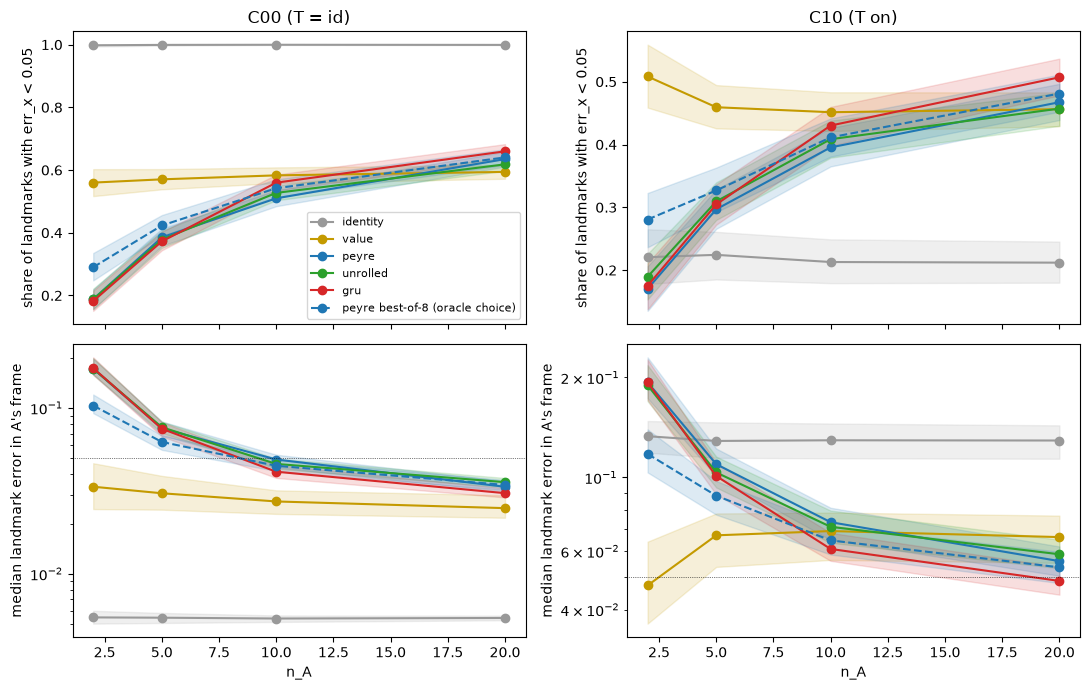

In [ ]:
colors = {"identity": "#999999", "value": "#c49a00", "peyre": "#1f77b4", "unrolled": "#2ca02c", "gru": "#d62728",
          "peyre_oracle_k": "#1f77b4"}
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
for j, cell in enumerate(["C00", "C10"]):
    for m in order:
        d = sm.loc[(sm.cell == cell) & (sm.method == m)].sort_values("n_a")
        ls = "--" if m == "peyre_oracle_k" else "-"
        lab = "peyre best-of-8 (oracle choice)" if m == "peyre_oracle_k" else m
        axes[0, j].plot(d.n_a, d.share, ls, marker="o", color=colors[m], label=lab)
        axes[0, j].fill_between(d.n_a, d.share_lo, d.share_hi, color=colors[m], alpha=0.15)
        axes[1, j].plot(d.n_a, d.med_err_x, ls, marker="o", color=colors[m])
        axes[1, j].fill_between(d.n_a, d.med_lo, d.med_hi, color=colors[m], alpha=0.15)
    axes[0, j].set_title(f"{cell} ({'T = id' if cell == 'C00' else 'T on'})")
    axes[0, j].set_ylabel("share of landmarks with err_x < 0.05")
    axes[1, j].set_ylabel("median landmark error in A's frame")
    axes[1, j].axhline(0.05, color="k", lw=0.5, ls=":")
    axes[1, j].set_yscale("log")
    axes[1, j].set_xlabel("n_A")
axes[0, 0].legend(fontsize=8)
fig.tight_layout()

### Training curves of the learned solvers (logged every 250 steps; also in MLflow)

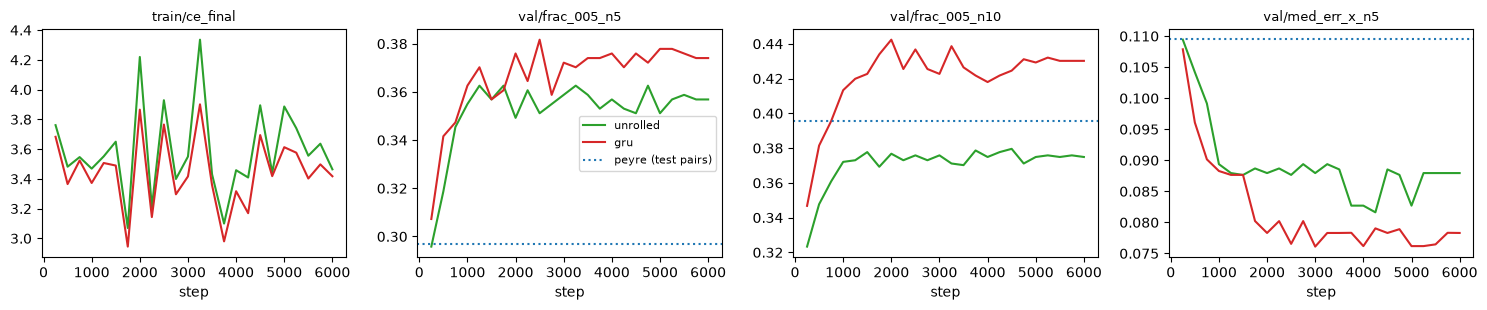

In [ ]:
peyre_c10 = sm.loc[(sm.cell == "C10") & (sm.method == "peyre")].set_index("n_a")
keys = ["train/ce_final", "val/frac_005_n5", "val/frac_005_n10", "val/med_err_x_n5"]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))
for name in ("unrolled", "gru"):
    cv = snaps[name].curves()
    for ax, k in zip(axes, keys):
        d = cv.loc[cv.key == k].sort_values("step")
        ax.plot(d.step, d.value, color=colors[name], label=name)
        ax.set_title(k, fontsize=9)
        ax.set_xlabel("step")
for ax, k, n in [(axes[1], "share", 5), (axes[2], "share", 10), (axes[3], "med_err_x", 5)]:
    ax.axhline(peyre_c10.loc[n, k], color=colors["peyre"], ls=":", label="peyre (test pairs)")
axes[1].legend(fontsize=8)
fig.tight_layout()

### 1d examples (C10, n_A = 5)

Per panel: A's function (its 128 query points, grey line) and A's context points (black); B's points in **B's own
frame** (u, y_B, light orange) and **placed in A's frame by the truth** (T(u), y_B on A's scale, light blue: they lie
on A's function); arrows from each A point to the B point the solver matched (green if the landmark error in A's
frame is < 0.05, red otherwise); the true partner u*_a (small blue tick on the u axis). The strip below shows each
A point's coupling row π_a· over B's u.

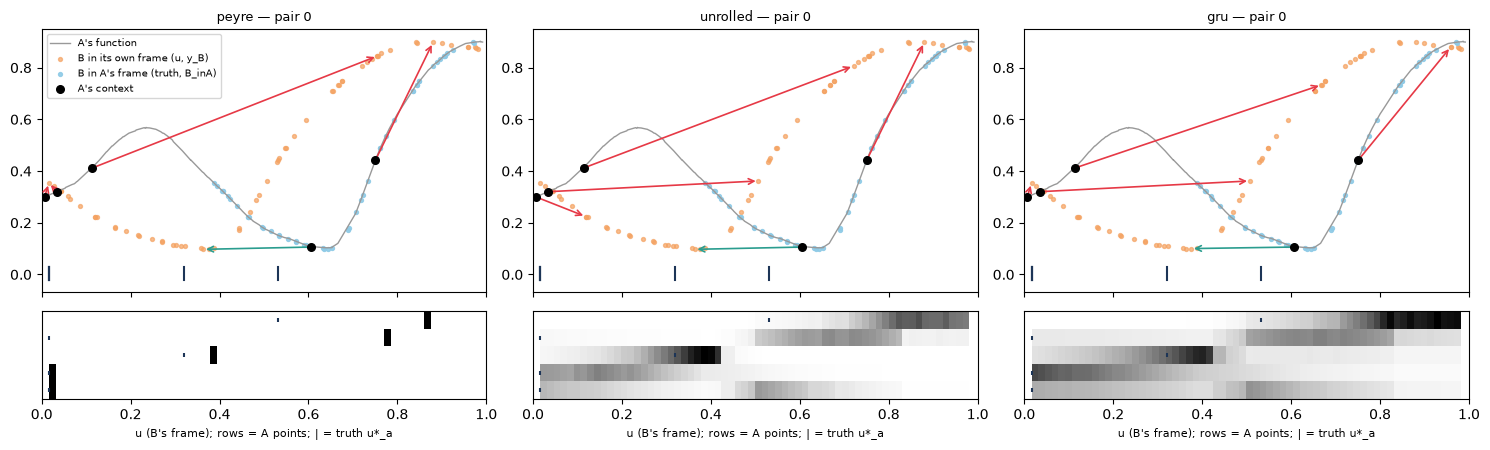

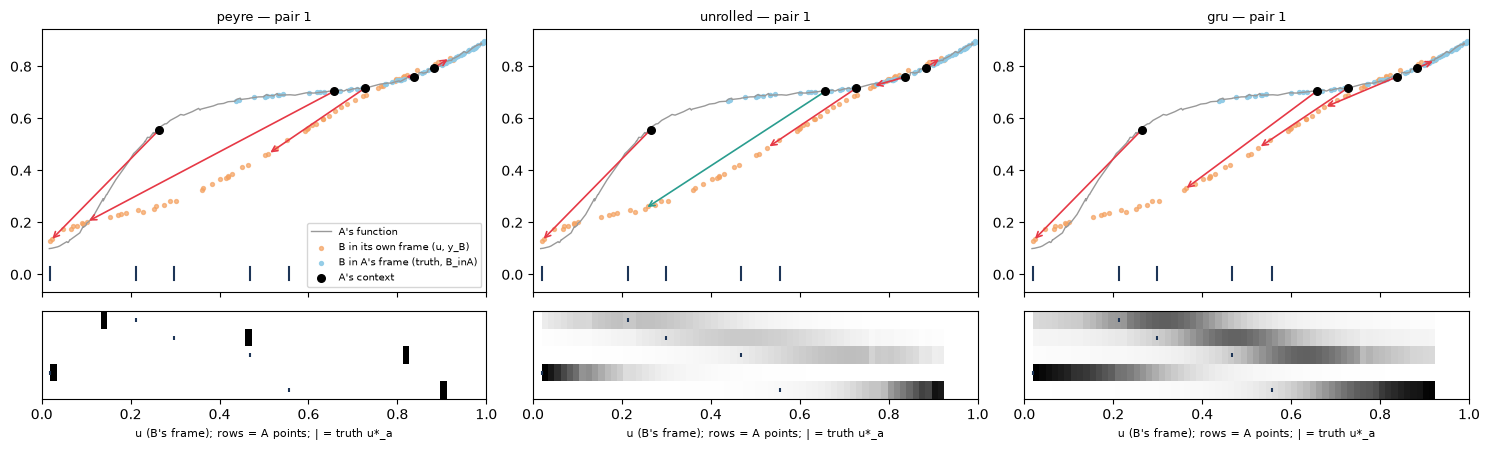

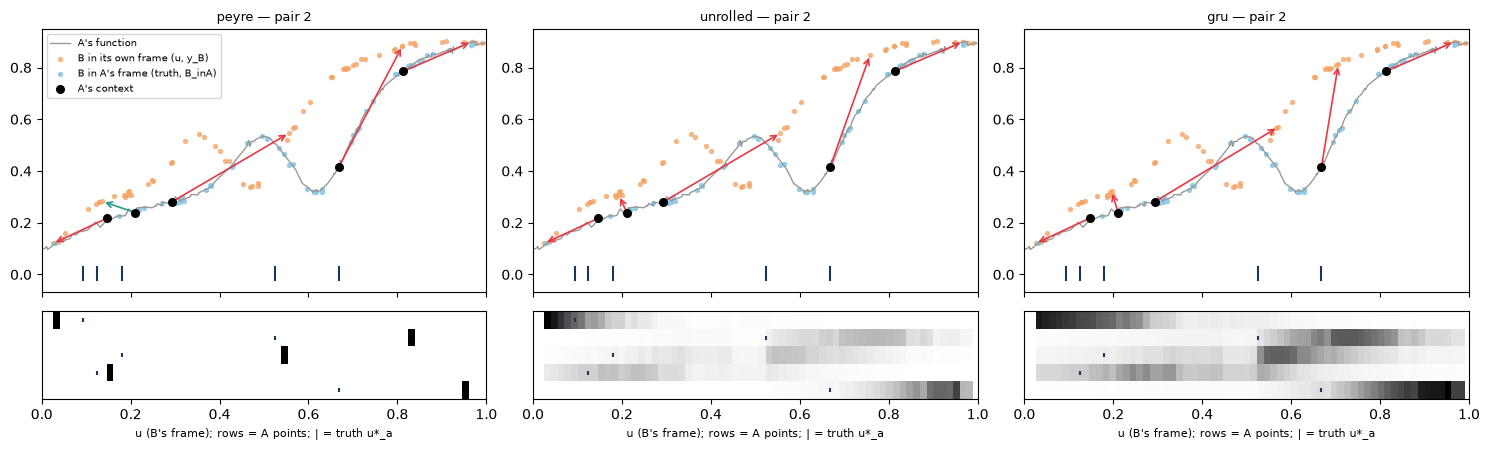

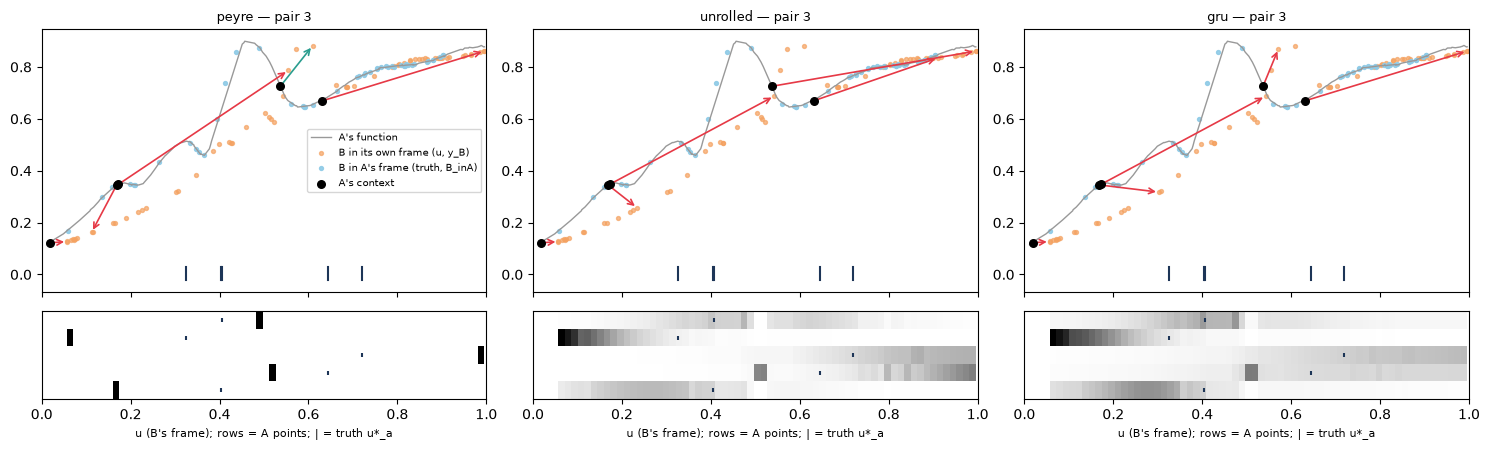

In [ ]:
def show_pair(ax, ax_pi, name, cell="C10", n=5, pair=0):
    pts, cps = snaps[name].table("points"), snaps[name].table("coupling")
    p = pts.loc[(pts.cell == cell) & (pts.n_a == n) & (pts.pair == pair)]
    B, A, Q = p.loc[p.role == "B"], p.loc[p.role == "A"].sort_values("i"), p.loc[p.role == "A_test"].sort_values("pos")
    ax.plot(Q.pos, Q.y, color="0.6", lw=1, label="A's function")
    ax.scatter(B.pos, B.y, s=8, color="#f4a261", alpha=0.7, label="B in its own frame (u, y_B)")
    ins = B.loc[B.flag]
    ax.scatter(ins.aux1, ins.aux2, s=8, color="#8ecae6", alpha=0.9, label="B in A's frame (truth, B_inA)")
    for _, a in A.iterrows():
        bh = B.iloc[(B.pos - a.aux2).abs().argmin()]
        ok = abs(bh.aux1 - a.pos) < 0.05
        ax.annotate("", xy=(bh.pos, bh.y), xytext=(a.pos, a.y),
                    arrowprops=dict(arrowstyle="->", color="#2a9d8f" if ok else "#e63946", lw=1.2))  # fmt: skip
        ax.plot([a.aux1, a.aux1], [-0.02, 0.03], color="#1d3557", lw=1.5)
    ax.scatter(A.pos, A.y, s=30, color="k", zorder=5, label="A's context")
    ax.set_xlim(0, 1)
    ax.set_title(f"{name} — pair {pair}", fontsize=9)
    c = cps.loc[(cps.cell == cell) & (cps.n_a == n) & (cps.pair == pair)]
    mat = c.pivot(index="row", columns="b", values="pi").to_numpy()
    u = B.sort_values("i").pos.to_numpy()
    o = np.argsort(u)
    ax_pi.imshow(mat[:, o], aspect="auto", cmap="Greys", extent=(u[o][0], u[o][-1], len(mat) - 0.5, -0.5))
    ax_pi.scatter(A.aux1, np.arange(len(A)), s=12, color="#1d3557", marker="|")
    ax_pi.set_xlim(0, 1)
    ax_pi.set_yticks([])
    ax_pi.set_xlabel("u (B's frame); rows = A points; | = truth u*_a", fontsize=8)


for pair in range(4):
    fig, axes = plt.subplots(2, 3, figsize=(15, 4.6), gridspec_kw={"height_ratios": [3, 1]}, sharex=True)
    for j, name in enumerate(["peyre", "unrolled", "gru"]):
        show_pair(axes[0, j], axes[1, j], name, pair=pair)
    axes[0, 0].legend(fontsize=7, loc="best")
    fig.tight_layout()

## Observations (2026-10-26, from the three snapshots above; 256 pairs per cell, N_B = 64)

- **Order-only GW recovers few landmarks.** C10 at n_A = 5: 30% of covered A points within 0.05 (Peyré 0.297
  [0.266, 0.329], unrolled 0.309 [0.280, 0.340], GRU 0.305 [0.272, 0.337]); median error 0.10–0.11 in A's frame.
  It rises with n_A (GRU 0.43 at n_A = 10, 0.51 at 20) but stays near 0.05 median only at n_A = 20.
- **It beats the identity guess under warps, but loses to the trivial value baseline.** In C10 the identity guess
  gets 0.22 (median 0.13); GW is better from n_A = 5. Nearest-value matching (`value`, ignores order entirely) gets
  0.45–0.51 at every n_A and beats every GW solver up to n_A = 10. With h = id the values carry metric information that
  sign relations throw away.
- **Even with T = id (C00) order-GW finds only 39% at n_A = 5.** A handful of A points' order relations are
  consistent with many monotone matchings; the GW energy cannot tell them apart. This is the core limit of an
  order-only coupling, not of the solver: the best of 8 restarts (oracle choice) adds only +0.01–0.10.
- **Learning adds little.** The learned solvers (trained with privileged supervision) are within the CIs of Peyré at
  n_A ≤ 5; the GRU operator is ahead at n_A = 10–20 (+0.035–0.04, CIs overlapping), so neither meets the "+0.10"
  criterion. The validation curves flatten after ~1,000–2,000 steps (unrolled ≈ 0.36, GRU ≈ 0.38 at n_A = 5): the
  model class saturates, not the training budget.
- **Calibration differs.** Peyré's couplings collapse to one B point per row (π-mass on the truth = share: confident
  and often wrong); the learned couplings stay spread (mass 0.22–0.43 < share), i.e. honest about the ambiguity,
  which a field / slot model downstream could use.
- **In the 1d examples** the typical failure is a *rank-for-rank* match: A's highest context point is sent to B's
  highest region although its true partner sits lower. Order relations among 5 points say "above the others", not
  "how high"; B also covers parts of the landscape that A's window does not (coverage 0.81 in C10).

## Verdict

By the pre-registered rule: **NOT USABLE** (best solver: unrolled, share 0.31, median 0.10 at C10, n_A = 5; it
beats `identity` on the share with separated CIs, but the median CIs touch (0.116 vs 0.115), so not even PARTIAL;
learned beats Peyré: no). Order-only GW does not give landmarks precise enough to seed the field at small n_A.

**Next (suggested):** give the coupling metric information that survives the prior's distortions: within-task
normalized y differences / quantiles as relation features (h is affine-per-window here; ablate under C01/C11),
combined with order; score against `value` as the bar to beat; and test whether the learned solvers' spread
couplings help a K > 1 / soft-seeded field.


In [ ]:
verdict(sm)

{'verdict': 'NOT USABLE',
 'best_solver': 'unrolled',
 'share': np.float64(0.309),
 'median_err_x': np.float32(0.1035),
 'learned_beats_peyre': {'unrolled': False, 'gru': False}}